<a href="https://colab.research.google.com/github/UmarMaishanu/Machine-Learning/blob/main/MLlab04_Pandas_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()          # pick customers.csv in the popup
df = pd.read_csv(list(uploaded.keys())[0])
df.head()

Saving customers.csv to customers (1).csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.shape)
df.info()
df.describe()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [5]:
for col in df.columns.drop('customerID'):
    print(col)
    print('-' * 30)
    print(df[col].value_counts(dropna=False).head(10))
    print('=' * 30)

gender
------------------------------
gender
Male      3555
Female    3488
Name: count, dtype: int64
SeniorCitizen
------------------------------
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
Partner
------------------------------
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents
------------------------------
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
tenure
------------------------------
tenure
1     613
72    362
2     238
3     200
4     176
71    170
5     133
7     131
8     123
9     119
Name: count, dtype: int64
PhoneService
------------------------------
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines
------------------------------
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService
------------------------------
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineS

In [6]:
# customerID is just a label, it tells the model nothing useful, so drop it
data = df.drop('customerID', axis=1)

# features = everything we use to predict; labels = what we want to predict
features = data.drop('Churn', axis=1)
labels = data['Churn']

print(features.shape)
print(labels.value_counts())
print(features.head())

(7043, 19)
Churn
No     5174
Yes    1869
Name: count, dtype: int64
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No 

In [7]:
labels = labels.map({'No': 0, 'Yes': 1})
print(labels.value_counts())
print(labels.value_counts(normalize=True).round(3))   # shows the % split

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [8]:
# errors='coerce' turns anything that isn't a number (like blank " ") into NaN
features['TotalCharges'] = pd.to_numeric(features['TotalCharges'], errors='coerce')

print(features['TotalCharges'].dtype)
print(features.isnull().sum()[features.isnull().sum() > 0])

float64
TotalCharges    11
dtype: int64


In [9]:
missing_rows = features[features['TotalCharges'].isnull()]
print(missing_rows[['tenure', 'MonthlyCharges', 'TotalCharges']])

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


In [10]:
# tenure = 0 means a brand-new customer who hasn't been billed yet -> total paid is 0
features['TotalCharges'] = features['TotalCharges'].fillna(0)

print(features['TotalCharges'].isnull().sum())   # should be 0
features['TotalCharges'].describe()

0


,TotalCharges
count,7043.000000
mean,2279.734304
std,2266.794470
min,0.000000
25%,398.550000
50%,1394.550000
75%,3786.600000
max,8684.800000


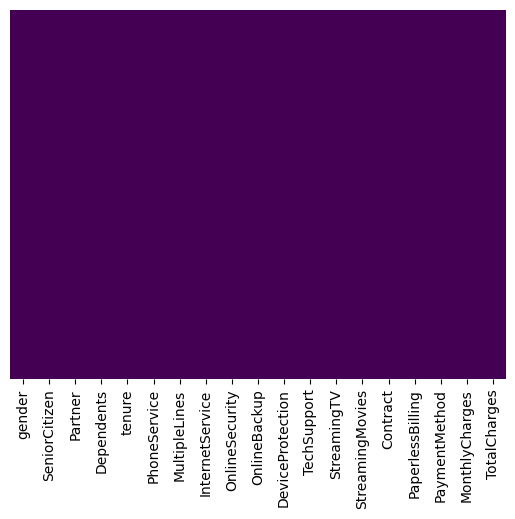

In [11]:
sns.heatmap(features.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.show()

In [12]:
# these columns only make sense if the customer has internet
internet_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in internet_cols:
    features[col] = features[col].replace('No internet service', 'No')

features['MultipleLines'] = features['MultipleLines'].replace('No phone service', 'No')

# check it worked
for col in internet_cols + ['MultipleLines']:
    print(col, features[col].unique())

OnlineSecurity ['No' 'Yes']
OnlineBackup ['Yes' 'No']
DeviceProtection ['No' 'Yes']
TechSupport ['No' 'Yes']
StreamingTV ['No' 'Yes']
StreamingMovies ['No' 'Yes']
MultipleLines ['No' 'Yes']


In [13]:
print('Duplicate rows:', features.duplicated().sum())

Duplicate rows: 40


            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


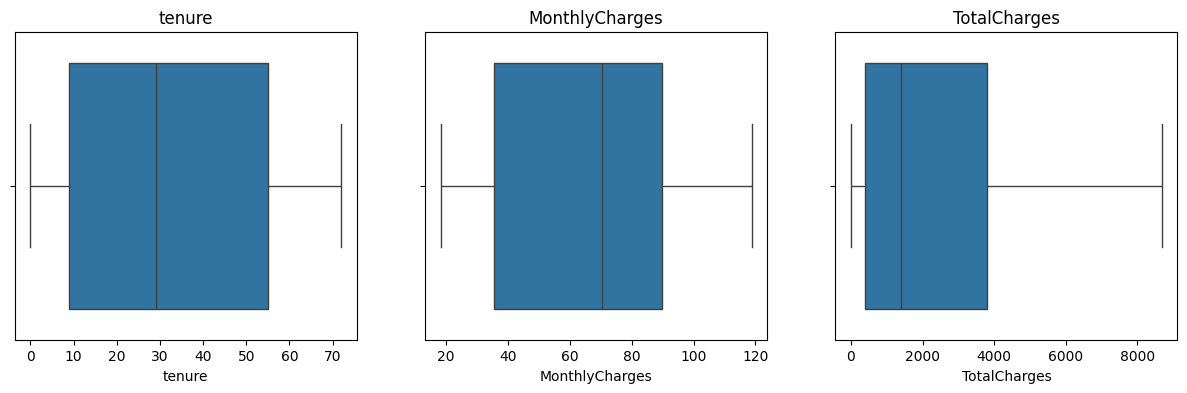

In [14]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print(features[num_cols].describe())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=features[col], ax=ax)
    ax.set_title(col)
plt.show()

In [15]:
for col in num_cols:
    q1 = features[col].quantile(0.25)
    q3 = features[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((features[col] < low) | (features[col] > high)).sum()
    print(f'{col}: allowed range [{low:.1f}, {high:.1f}] -> outliers: {n_out}')

tenure: allowed range [-60.0, 124.0] -> outliers: 0
MonthlyCharges: allowed range [-46.0, 171.4] -> outliers: 0
TotalCharges: allowed range [-4683.5, 8868.7] -> outliers: 0


In [16]:
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling',
               'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
               'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in binary_cols:
    features[col] = features[col].map({'No': 0, 'Yes': 1})

features['gender'] = features['gender'].map({'Female': 0, 'Male': 1})

print(features[binary_cols + ['gender']].isnull().sum().sum())   # should be 0

0


In [21]:
if features['Contract'].dtype == 'object' or str(features['Contract'].dtype) == 'str':
    features['Contract'] = features['Contract'].map({'Month-to-month': 0,
                                                     'One year': 1,
                                                     'Two year': 2})

print(features['Contract'].value_counts())
print(features['Contract'].dtype)
print(features.isnull().sum().sum())

Contract
0    3875
2    1695
1    1473
Name: count, dtype: int64
int64
0


In [17]:
features = pd.get_dummies(features, columns=['InternetService', 'PaymentMethod'],
                          drop_first=True, dtype=int)

print(features.shape)
print(features.columns.tolist())
features.head()

(7043, 22)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,StreamingMovies,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,0,Month-to-month,1,29.85,29.85,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,0,One year,0,56.95,1889.50,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,0,Month-to-month,1,53.85,108.15,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,0,One year,0,42.30,1840.75,0,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,Month-to-month,1,70.70,151.65,1,0,0,1,0


In [19]:
features.info()
print(features.isnull().sum().sum())   # should be 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   MultipleLines                          7043 non-null   int64  
 7   OnlineSecurity                         7043 non-null   int64  
 8   OnlineBackup                           7043 non-null   int64  
 9   DeviceProtection                       7043 non-null   int64  
 10  TechSupport                            7043 non-null   int64  
 11  Stre

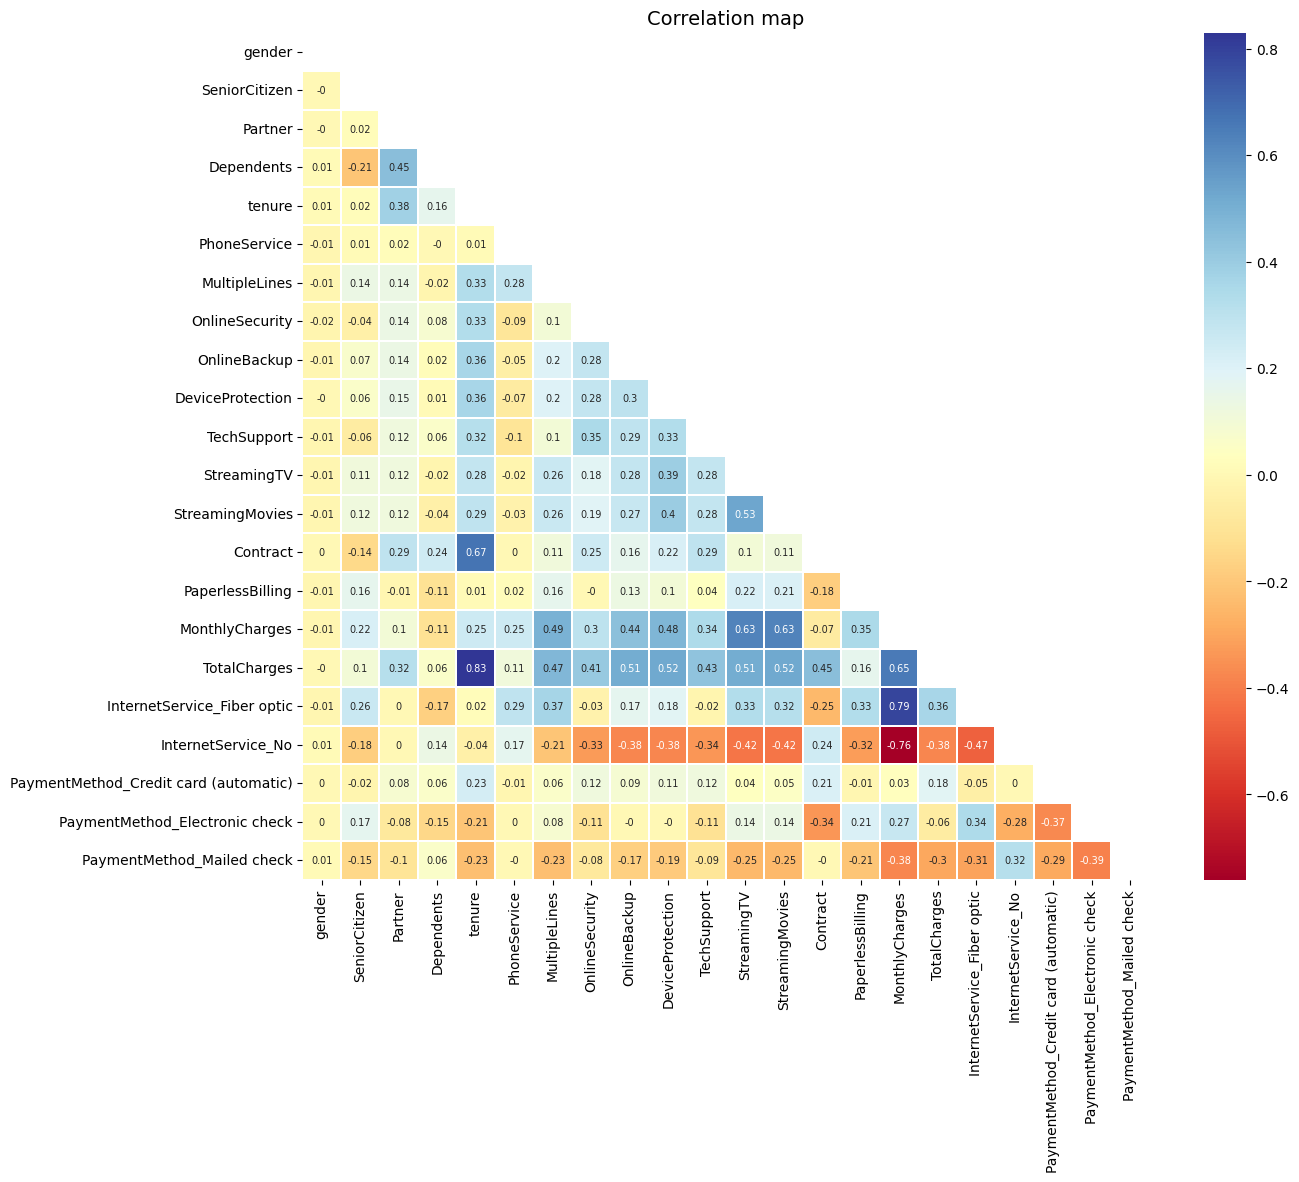

In [22]:
var_corr = features.corr().round(2)
mask = np.triu(np.ones_like(var_corr, dtype=bool))   # hide the mirrored upper half

plt.figure(figsize=(14, 11))
sns.heatmap(var_corr, mask=mask, square=True, annot=True,
            annot_kws={'size': 7}, cmap='RdYlBu', linewidths=.1)
plt.title('Correlation map', fontsize=14)
plt.show()

In [23]:
corr_pairs = var_corr.where(~mask).stack()          # one entry per pair
strong = corr_pairs[corr_pairs.abs() > 0.7].sort_values(ascending=False)
print(strong)

TotalCharges                 tenure            0.83
InternetService_Fiber optic  MonthlyCharges    0.79
InternetService_No           MonthlyCharges   -0.76
dtype: float64


In [24]:
with_target = features.copy()
with_target['Churn'] = labels
print(with_target.corr()['Churn'].drop('Churn').sort_values())

Contract                                -0.396713
tenure                                  -0.352229
InternetService_No                      -0.227890
TotalCharges                            -0.198324
OnlineSecurity                          -0.171226
TechSupport                             -0.164674
Dependents                              -0.164221
Partner                                 -0.150448
PaymentMethod_Credit card (automatic)   -0.134302
PaymentMethod_Mailed check              -0.091683
OnlineBackup                            -0.082255
DeviceProtection                        -0.066160
gender                                  -0.008612
PhoneService                             0.011942
MultipleLines                            0.040102
StreamingMovies                          0.061382
StreamingTV                              0.063228
SeniorCitizen                            0.150889
PaperlessBilling                         0.191825
MonthlyCharges                           0.193356


In [25]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print(features[num_cols].describe().round(2))

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     32.37           64.76       2279.73
std      24.56           30.09       2266.79
min       0.00           18.25          0.00
25%       9.00           35.50        398.55
50%      29.00           70.35       1394.55
75%      55.00           89.85       3786.60
max      72.00          118.75       8684.80


In [26]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scale_std = StandardScaler()
features[num_cols] = scale_std.fit_transform(features[num_cols])

print(features[num_cols].describe().round(2))

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     -0.00           -0.00         -0.00
std       1.00            1.00          1.00
min      -1.32           -1.55         -1.01
25%      -0.95           -0.97         -0.83
50%      -0.14            0.19         -0.39
75%       0.92            0.83          0.66
max       1.61            1.79          2.83


In [27]:
# We use a copy so the main data keeps the standard scaling from cell 24
demo_mm = df[['tenure', 'MonthlyCharges']].copy()
demo_mm['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

scale_mm = MinMaxScaler()
demo_mm[num_cols] = scale_mm.fit_transform(demo_mm[num_cols])

print(demo_mm.describe().round(2))

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean      0.45            0.46          0.26
std       0.34            0.30          0.26
min       0.00            0.00          0.00
25%       0.12            0.17          0.05
50%       0.40            0.52          0.16
75%       0.76            0.71          0.44
max       1.00            1.00          1.00


In [28]:
from sklearn.model_selection import train_test_split

features_train, features_test, labels_train, labels_test = train_test_split(
    features, labels,
    test_size=0.2,
    random_state=0,
    stratify=labels      # keeps the same churn % in both parts
)

print(features.shape)
print(features_train.shape)
print(features_test.shape)

(7043, 22)
(5634, 22)
(1409, 22)


In [29]:
print('Train:', labels_train.value_counts(normalize=True).round(3).to_dict())
print('Test: ', labels_test.value_counts(normalize=True).round(3).to_dict())

Train: {0: 0.735, 1: 0.265}
Test:  {0: 0.735, 1: 0.265}


In [30]:
print('Missing in train:', features_train.isnull().sum().sum())
print('Missing in test: ', features_test.isnull().sum().sum())
print('Non-numeric columns:', features_train.select_dtypes(exclude='number').columns.tolist())

Missing in train: 0
Missing in test:  0
Non-numeric columns: []
